# 01 ? Titanic: exploratory data analysis

Load the Titanic dataset, keep a local CSV snapshot for offline reuse, and explore missing values, distributions, survival relationships, and numeric correlations.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

analytics_dir = Path.cwd()
if analytics_dir.name.lower() != "analytics":
    analytics_dir = analytics_dir / "analytics"
analytics_dir.mkdir(parents=True, exist_ok=True)
csv_path = analytics_dir / "titanic.csv"

if not csv_path.exists():
    df = sns.load_dataset("titanic")
    df.to_csv(csv_path, index=False)
    print(f"Saved seaborn dataset to {csv_path.resolve()}")
else:
    print(f"Using local snapshot: {csv_path.resolve()}")

# Read back from the snapshot so this and later runs use the same local data.
df = pd.read_csv(csv_path)
print(f"Dataset successfully loaded. Shape: {df.shape}")
df.head()

Using local snapshot: C:\zepto-data-ai-platform\analytics\titanic.csv
Dataset successfully loaded. Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 2. Missing-value strategy

Drop the heavily incomplete `deck` column, remove records missing categorical embarkation values, and median-impute `age`.

In [2]:
print("Initial Missing Values:\n", df.isnull().sum())

if "deck" in df.columns and df["deck"].isna().mean() > 0.70:
    df = df.drop(columns=["deck"])

df = df.dropna(subset=["embarked", "embark_town"])
age_median = df["age"].median()
df["age"] = df["age"].fillna(age_median)

print("\nRemaining Missing Values:\n", df.isnull().sum())

Initial Missing Values:
 survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Remaining Missing Values:
 survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64


## 3. Univariate analysis

Compare age and fare distributions, quantify skewness, and count fare outliers using the IQR rule.

Age Skewness: 0.5080100783148628
Fare Skewness: 4.801440211044191
Number of fare outliers detected via IQR: 114


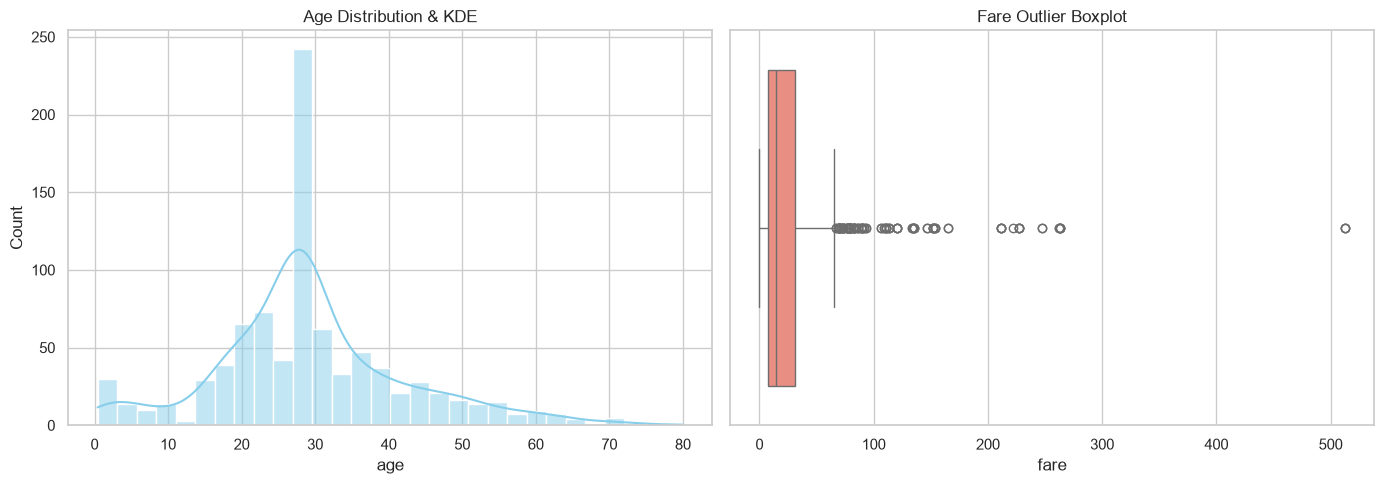

In [3]:
print("Age Skewness:", df["age"].skew())
print("Fare Skewness:", df["fare"].skew())

Q1 = df["fare"].quantile(0.25)
Q3 = df["fare"].quantile(0.75)
IQR = Q3 - Q1
outliers_fare = df[(df["fare"] < (Q1 - 1.5 * IQR)) | (df["fare"] > (Q3 + 1.5 * IQR))]
print(f"Number of fare outliers detected via IQR: {len(outliers_fare)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df["age"], kde=True, ax=axes[0], color="skyblue")
axes[0].set_title("Age Distribution & KDE")
sns.boxplot(x=df["fare"], ax=axes[1], color="salmon")
axes[1].set_title("Fare Outlier Boxplot")
plt.tight_layout()
plt.show()

## 4. Bivariate analysis

Compare survival by sex and class and inspect age by survival status. These plots describe associations, not causal effects.

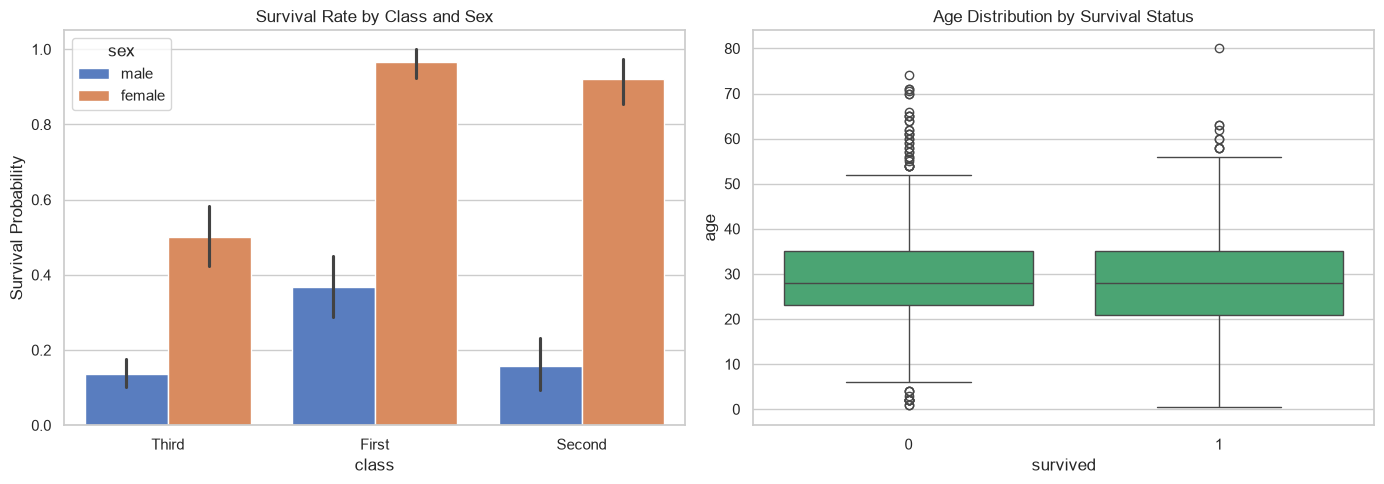

Survival Probability Breakdown:
     class     sex  survived
0   First  female  0.967391
1   First    male  0.368852
2  Second  female  0.921053
3  Second    male  0.157407
4   Third  female  0.500000
5   Third    male  0.135447


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=df, x="class", y="survived", hue="sex", ax=axes[0], palette="muted")
axes[0].set_title("Survival Rate by Class and Sex")
axes[0].set_ylabel("Survival Probability")

sns.boxplot(data=df, x="survived", y="age", ax=axes[1], color="mediumseagreen")
axes[1].set_title("Age Distribution by Survival Status")

plt.tight_layout()
plt.show()

survival_summary = df.groupby(["class", "sex"], observed=True)["survived"].mean().reset_index()
print("Survival Probability Breakdown:\n", survival_summary)

## 5. Correlation heatmap

Compute and plot a labeled 6 ? 6 correlation matrix for the numeric features.

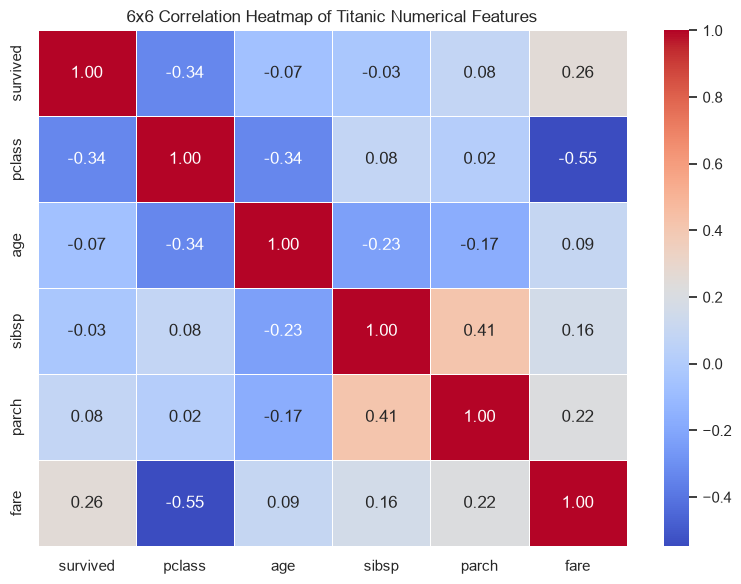

In [5]:
numeric_cols = ["survived", "pclass", "age", "sibsp", "parch", "fare"]
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("6x6 Correlation Heatmap of Titanic Numerical Features")
plt.tight_layout()
plt.show()